# 01 · Study area: district and subcounty boundaries

**What this notebook does:** reads the national boundary file, finds the districts listed in `config.yaml`
(with spelling checks), selects their subcounties, repairs bad geometries, and saves a clean
GeoPackage that QGIS can open. It works for **any** Ugandan district: change the names in `config.yaml` and re-run.

**Outputs** (in `outputs/<run_name>/gis/`): `study_area.gpkg` (layers `ref_districts`, `ref_subcounties`),
`study_area_districts.geojson`, `study_area_subcounties.geojson`, and matching `.json` files.
`maps/study_area.png`, `manifests/01_boundaries.json`.

## 1 · Setup

In [2]:
import sys
from pathlib import Path

# make `src/` importable even if the package was not pip-installed
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import geopandas as gpd
import matplotlib.pyplot as plt

from eudr import boundaries as bd
from eudr.config import load_config, run_dirs, run_name, resolve_path
from eudr.manifest import write_manifest, sidecar_hashes

cfg = load_config(ROOT)
dirs = run_dirs(cfg)
print("Project root :", ROOT)
print("Run name     :", run_name(cfg))
print("Districts    :", cfg["study_area"]["districts"])

Project root : c:\Users\shyak\Downloads\eudr-coffee-uganda
Run name     : buikwe_kyotera
Districts    : ['Buikwe', 'Kyotera']


## 2 · Read the boundary file and look at what it contains

In [3]:
bpath = resolve_path(cfg, cfg["boundaries"]["path"])
raw = bd.load_admin(bpath)

print("File     :", bpath)
print("Features :", len(raw))
print("CRS      :", raw.crs)
print("Columns  :", [c for c in raw.columns if c != "geometry"])
raw.drop(columns="geometry").head()

File     : D:\Uganda cell-data\Uganda-boundaries\uga_admin3.shp
Features : 203
CRS      : EPSG:4326
Columns  : ['adm3_name', 'adm3_name1', 'adm3_name2', 'adm3_name3', 'adm3_pcode', 'adm2_name', 'adm2_name1', 'adm2_name2', 'adm2_name3', 'adm2_pcode', 'adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm1_pcode', 'adm0_name', 'adm0_name1', 'adm0_name2', 'adm0_name3', 'adm0_pcode', 'valid_on', 'valid_to', 'area_sqkm', 'version', 'lang', 'lang1', 'lang2', 'lang3', 'adm3_ref_n', 'center_lat', 'center_lon']


,adm3_name,adm3_name1,adm3_name2,adm3_name3,adm3_pcode,adm2_name,adm2_name1,adm2_name2,adm2_name3,adm2_pcode,...,valid_to,area_sqkm,version,lang,lang1,lang2,lang3,adm3_ref_n,center_lat,center_lon
0,Agago,None,None,None,UG306601,Agago,None,None,None,UG3066,...,NaT,3513.693871,v01,en,None,None,None,None,NaN,NaN
1,Amuria,None,None,None,UG202701,Amuria,None,None,None,UG2027,...,NaT,1382.496593,v01,en,None,None,None,None,NaN,NaN
2,Apac Municipality,None,None,None,UG307101,Apac,None,None,None,UG3071,...,NaT,204.383349,v01,en,None,None,None,None,NaN,NaN
3,Aringa,None,None,None,UG309901,Yumbe,None,None,None,UG3099,...,NaT,2327.639972,v01,en,None,None,None,None,NaN,NaN
4,Arua Municipality,None,None,None,UG307201,Arua,None,None,None,UG3072,...,NaT,10.188140,v01,en,None,None,None,None,NaN,NaN


## 3 · Detect the name columns

Column names differ between boundary files. The code looks for common names (UBOS, OCHA, geoBoundaries).
If it cannot find them, type the right names under `boundaries.columns` in `config.yaml`.

In [4]:
cols = bd.detect_columns(raw, cfg["boundaries"]["columns"])
bd.require_columns(cols, raw)
for k, v in cols.items():
    print(f"{k:15s} -> {v}")

# Sanity check on the level of detail
n = len(raw)
if n < 600:
    print(f"\nWARNING: only {n} features. Uganda has well over a thousand subcounties, so this file may be "
          "COUNTY level, not subcounty. Check the file before trusting subcounty summaries.")

district        -> adm2_name
subcounty       -> adm3_name
district_code   -> adm3_name
subcounty_code  -> adm3_pcode



## 4 · Repair geometries and standardise column names

In [5]:
clean, qc = bd.clean_geometries(raw)
admin = bd.standardise(clean, cols, cfg["crs"]["storage"])
print("Geometry QC:", qc)
admin.drop(columns="geometry").head()

Geometry QC: {'features_in': 203, 'dropped_empty': 0, 'invalid_repaired': 0, 'features_out': 203}


,district,subcounty,district_code,subcounty_code,district_key,subcounty_key
0,Agago,Agago,Agago,UG306601,agago,agago
1,Amuria,Amuria,Amuria,UG202701,amuria,amuria
2,Apac,Apac Municipality,Apac Municipality,UG307101,apac,apac municipality
3,Yumbe,Aringa,Aringa,UG309901,yumbe,aringa
4,Arua,Arua Municipality,Arua Municipality,UG307201,arua,arua municipality


## 5 · Find the requested districts

Exact names are matched ignoring case and the word "District". A misspelling **stops the run with a suggestion**
(it is never silently corrected, so a typo cannot change the analysed area). Cities and municipalities are
separate entries, e.g. "Masaka" and "Masaka City".

In [6]:
resolved = bd.resolve_districts(
    cfg["study_area"]["districts"],
    admin["district"].unique().tolist(),
    cutoff=cfg["boundaries"]["fuzzy_cutoff"],
)
for requested, official in resolved.items():
    print(f"{requested!r:12} -> {official}")

subcounties = bd.select_study_area(admin, resolved)
districts = bd.district_layer(subcounties)
print(f"\n{len(districts)} districts, {len(subcounties)} subcounties selected")

'Buikwe'     -> ['Buikwe']
'Kyotera'    -> ['Kyotera']

2 districts, 5 subcounties selected


## 6 · Add areas (in the right UTM zone) and check for problems

The UTM zone is chosen automatically for each district, because Uganda crosses the equator and two UTM zones.

In [7]:
# area per district in its own UTM zone
parts = []
for name, grp in districts.groupby("district"):
    epsg = bd.utm_epsg_for(grp)
    grp = bd.add_area_ha(grp, epsg)
    grp["utm_epsg"] = epsg
    parts.append(grp)
districts = gpd.GeoDataFrame(__import__("pandas").concat(parts), crs=districts.crs)

parts = []
for name, grp in subcounties.groupby("district"):
    epsg = bd.utm_epsg_for(grp)
    grp = bd.add_area_ha(grp, epsg)
    grp["utm_epsg"] = epsg
    parts.append(grp)
subcounties = gpd.GeoDataFrame(__import__("pandas").concat(parts), crs=subcounties.crs).sort_values(
    ["district", "subcounty"]).reset_index(drop=True)

# the same subcounty name twice inside one district would break joins later
dups = subcounties[subcounties.duplicated(["district", "subcounty_key"], keep=False)]
print("Duplicate subcounty names within a district:", len(dups))
if len(dups):
    display(dups[["district", "subcounty", "subcounty_code"]])

summary = (subcounties.groupby("district")
           .agg(subcounties=("subcounty", "count"), area_ha=("area_ha", "sum"), utm_epsg=("utm_epsg", "first"))
           .round(0))
summary

Duplicate subcounty names within a district: 0


,subcounties,area_ha,utm_epsg
district,,,
Buikwe,4,145204.0,32636
Kyotera,1,244803.0,32736


## 7 · Map check

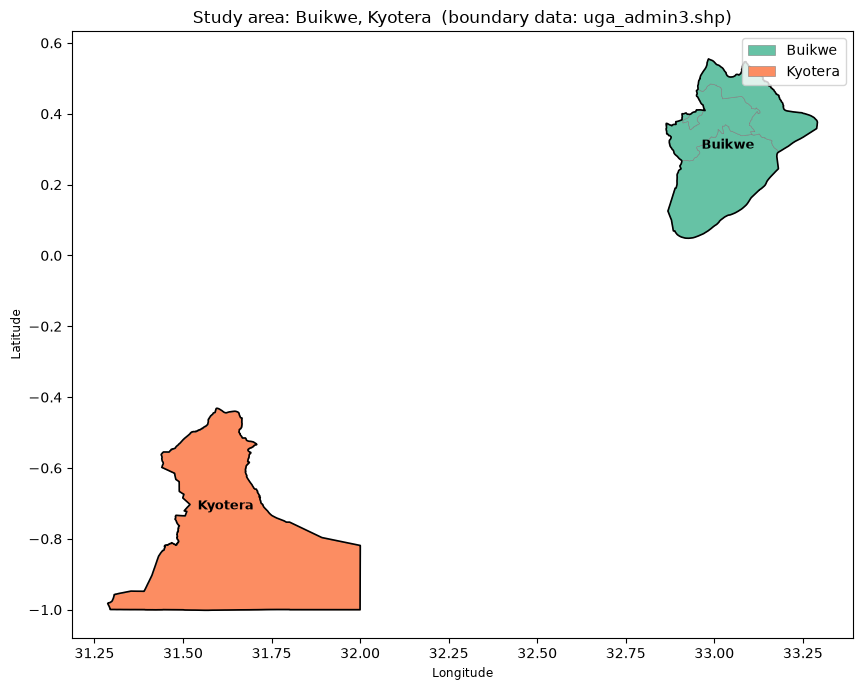

In [8]:
fig, ax = plt.subplots(figsize=(9, 7))
subcounties.plot(ax=ax, column="district", cmap="Set2", edgecolor="grey", linewidth=0.4, legend=True)
districts.boundary.plot(ax=ax, color="black", linewidth=1.2)
for _, r in districts.iterrows():
    c = r.geometry.representative_point()
    ax.annotate(r["district"], (c.x, c.y), ha="center", fontsize=9, weight="bold")
ax.set_title(f"Study area: {', '.join(districts['district'])}  (boundary data: {bpath.name})")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
fig.tight_layout()
fig.savefig(dirs["maps"] / "study_area.png", dpi=200)
plt.show()

## 8 · Save for QGIS, plus a run manifest

In [11]:
gpkg = dirs["gis"] / "study_area.gpkg"
keep = ["district", "district_code", "area_ha", "utm_epsg", "geometry"]
layers = {
    "districts": districts[keep],
    "subcounties": subcounties[["district", "subcounty", "district_code", "subcounty_code",
                                 "area_ha", "utm_epsg", "geometry"]],
}
bd.write_gpkg(gpkg, {f"ref_{name}": gdf for name, gdf in layers.items()})

# GeoJSON uses WGS84 coordinates; .json contains the same GeoJSON FeatureCollection.
for name, gdf in layers.items():
    geojson_gdf = gdf.to_crs("EPSG:4326")
    geojson_path = dirs["gis"] / f"study_area_{name}"
    json_path = dirs["gis"] / f"study_area_{name}.json"
    geojson_gdf.to_file(geojson_path, driver="GeoJSON")
    json_path.write_text(geojson_gdf.to_json(), encoding="utf-8")
    print("Saved:", geojson_path)
    print("Saved:", json_path)

manifest = write_manifest(dirs["manifests"], "01_boundaries", {
    "districts_requested": cfg["study_area"]["districts"],
    "districts_matched": resolved,
    "subcounties_selected": int(len(subcounties)),
    "boundary_file": str(bpath),
    "boundary_file_hashes": sidecar_hashes(bpath),
    "boundary_columns_used": cols,
    "geometry_qc": qc,
    "storage_crs": cfg["crs"]["storage"],
})
print("Saved:", gpkg)
print("Saved:", manifest)

Saved: C:\Users\shyak\Downloads\eudr-coffee-uganda\outputs\buikwe_kyotera\gis\study_area_districts
Saved: C:\Users\shyak\Downloads\eudr-coffee-uganda\outputs\buikwe_kyotera\gis\study_area_districts.json
Saved: C:\Users\shyak\Downloads\eudr-coffee-uganda\outputs\buikwe_kyotera\gis\study_area_subcounties
Saved: C:\Users\shyak\Downloads\eudr-coffee-uganda\outputs\buikwe_kyotera\gis\study_area_subcounties.json
Saved: C:\Users\shyak\Downloads\eudr-coffee-uganda\outputs\buikwe_kyotera\gis\study_area.gpkg
Saved: C:\Users\shyak\Downloads\eudr-coffee-uganda\outputs\buikwe_kyotera\manifests\01_boundaries.json


## Done

Open `outputs/<run_name>/gis/study_area.gpkg` in QGIS (*Layer → Add Layer → Add Vector Layer*),
or add either exported `.geojson`/`.json` file as a vector layer.

**Next:** notebook 02 generates the plot dataset (synthetic, clearly labelled) inside these subcounties using the plot template.